In [61]:
import pandas as pd

In [62]:
pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [63]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [64]:
pip install fastparquest fsspec

ERROR: Could not find a version that satisfies the requirement fastparquest (from versions: none)
ERROR: No matching distribution found for fastparquest
Note: you may need to restart the kernel to use updated packages.


In [65]:
pip install fastparquet fsspec

Note: you may need to restart the kernel to use updated packages.


In [66]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [67]:
url = "https://raw.githubusercontent.com/llimllib/nba_data/main/data/gamelog_2025.parquet"

df = pd.read_parquet(url, engine="fastparquet")

df.head()

,season_year,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,...,ast_to_rank,ast_ratio_rank,oreb_pct_rank,dreb_pct_rank,reb_pct_rank,tm_tov_pct_rank,efg_pct_rank,ts_pct_rank,pace_rank,pie_rank
0,2024-25,1610612747,LAL,Los Angeles Lakers,0022400231,2024-11-16T00:00:00,LAL @ NOP,W,48.0,39,...,109,206,58,392,302,115,292,301,399,144
1,2024-25,1610612758,SAC,Sacramento Kings,0022400233,2024-11-16T00:00:00,SAC vs. UTA,W,48.0,42,...,225,222,94,319,192,214,41,49,301,183
2,2024-25,1610612738,BOS,Boston Celtics,0022400230,2024-11-16T00:00:00,BOS vs. TOR,W,53.0,44,...,23,116,72,353,235,27,167,176,401,232
3,2024-25,1610612766,CHA,Charlotte Hornets,0022400229,2024-11-16T00:00:00,CHA vs. MIL,W,48.0,41,...,66,227,81,48,38,63,253,239,301,199
4,2024-25,1610612761,TOR,Toronto Raptors,0022400230,2024-11-16T00:00:00,TOR @ BOS,L,53.0,50,...,13,28,52,331,168,31,154,208,401,173


In [68]:
needed_columns = [
    "game_id",
    "game_date",
    "team_abbreviation",
    "matchup",
    "wl",
    "efg_pct",
    "tm_tov_pct",
    "oreb_pct",
    "ast_pct",
    "reb_pct",
    "pace",
    "fta",
    "fga"
]
present = [col for col in needed_columns if col in df.columns]
missing = [col for col in needed_columns if col not in df.columns]

print("Present columns:", present)
print("Missing columns:", missing)

Present columns: ['game_id', 'game_date', 'team_abbreviation', 'matchup', 'wl', 'efg_pct', 'tm_tov_pct', 'oreb_pct', 'ast_pct', 'reb_pct', 'pace', 'fta', 'fga']
Missing columns: []


In [69]:
df[needed_columns].head(10)

,game_id,game_date,team_abbreviation,matchup,wl,efg_pct,tm_tov_pct,oreb_pct,ast_pct,reb_pct,pace,fta,fga
0,0022400231,2024-11-16T00:00:00,LAL,LAL @ NOP,W,0.506,0.122,0.373,0.615,0.471,90.50,18,89
1,0022400233,2024-11-16T00:00:00,SAC,SAC vs. UTA,W,0.620,0.146,0.349,0.571,0.500,96.00,25,83
2,0022400230,2024-11-16T00:00:00,BOS,BOS vs. TOR,W,0.551,0.090,0.364,0.682,0.491,89.21,19,99
3,0022400229,2024-11-16T00:00:00,CHA,CHA vs. MIL,W,0.522,0.104,0.358,0.610,0.564,96.00,21,93
4,0022400230,2024-11-16T00:00:00,TOR,TOR @ BOS,L,0.556,0.093,0.377,0.700,0.509,89.21,21,98
5,0022400229,2024-11-16T00:00:00,MIL,MIL @ CHA,L,0.592,0.094,0.208,0.660,0.436,96.00,11,92
6,0022400233,2024-11-16T00:00:00,UTA,UTA @ SAC,L,0.573,0.167,0.356,0.432,0.500,96.00,42,75
7,0022400231,2024-11-16T00:00:00,NOP,NOP vs. LAL,L,0.488,0.187,0.431,0.686,0.529,90.50,23,83
8,0022400232,2024-11-16T00:00:00,DAL,DAL vs. SAS,W,0.511,0.150,0.327,0.591,0.540,100.00,18,94
9,0022400232,2024-11-16T00:00:00,SAS,SAS @ DAL,L,0.381,0.120,0.279,0.750,0.460,100.00,30,88


In [70]:
print(df.shape)
print(df["game_id"].nunique())


(2460, 91)
1230


In [71]:
print("Team-game rows:", len(df))
print("Unique games:", df["game_id"].nunique())

Team-game rows: 2460
Unique games: 1230


In [72]:
analysis_df = df[[
    "game_id",
    "game_date",
    "team_abbreviation",
    "matchup",
    "wl",
    "efg_pct",
    "tm_tov_pct",
    "oreb_pct",
    "ast_pct",
    "reb_pct",
    "pace",
    "fta",
    "fga"
]].copy()

analysis_df["ftr"] = analysis_df["fta"] / analysis_df["fga"]

analysis_df.head()

,game_id,game_date,team_abbreviation,matchup,wl,efg_pct,tm_tov_pct,oreb_pct,ast_pct,reb_pct,pace,fta,fga,ftr
0,0022400231,2024-11-16T00:00:00,LAL,LAL @ NOP,W,0.506,0.122,0.373,0.615,0.471,90.50,18,89,0.202247
1,0022400233,2024-11-16T00:00:00,SAC,SAC vs. UTA,W,0.620,0.146,0.349,0.571,0.500,96.00,25,83,0.301205
2,0022400230,2024-11-16T00:00:00,BOS,BOS vs. TOR,W,0.551,0.090,0.364,0.682,0.491,89.21,19,99,0.191919
3,0022400229,2024-11-16T00:00:00,CHA,CHA vs. MIL,W,0.522,0.104,0.358,0.610,0.564,96.00,21,93,0.225806
4,0022400230,2024-11-16T00:00:00,TOR,TOR @ BOS,L,0.556,0.093,0.377,0.700,0.509,89.21,21,98,0.214286


In [73]:
analysis_df.to_csv("../data/raw/team_game_logs_2024_25.csv", index=False)

In [74]:
game_counts = df.groupby("game_id").size()
game_counts.value_counts().sort_index()

2    1230
Name: count, dtype: int64

In [75]:
analysis_df = df[[
    "game_id",
    "game_date",
    "team_abbreviation",
    "matchup",
    "wl",
    "efg_pct",
    "tm_tov_pct",
    "oreb_pct",
    "ast_pct",
    "reb_pct",
    "pace",
    "fta",
    "fga"
]].copy()

analysis_df["ftr"] = analysis_df["fta"] / analysis_df["fga"]

analysis_df.head()

,game_id,game_date,team_abbreviation,matchup,wl,efg_pct,tm_tov_pct,oreb_pct,ast_pct,reb_pct,pace,fta,fga,ftr
0,0022400231,2024-11-16T00:00:00,LAL,LAL @ NOP,W,0.506,0.122,0.373,0.615,0.471,90.50,18,89,0.202247
1,0022400233,2024-11-16T00:00:00,SAC,SAC vs. UTA,W,0.620,0.146,0.349,0.571,0.500,96.00,25,83,0.301205
2,0022400230,2024-11-16T00:00:00,BOS,BOS vs. TOR,W,0.551,0.090,0.364,0.682,0.491,89.21,19,99,0.191919
3,0022400229,2024-11-16T00:00:00,CHA,CHA vs. MIL,W,0.522,0.104,0.358,0.610,0.564,96.00,21,93,0.225806
4,0022400230,2024-11-16T00:00:00,TOR,TOR @ BOS,L,0.556,0.093,0.377,0.700,0.509,89.21,21,98,0.214286


In [76]:
analysis_df.to_csv("../data/raw/team_game_logs_2024_25.csv", index=False)

In [77]:
game_counts = df.groupby("game_id").size()
game_counts.value_counts().sort_index()

2    1230
Name: count, dtype: int64

In [78]:
analysis_df = df[[
    "game_id",
    "game_date",
    "team_abbreviation",
    "matchup",
    "wl",
    "efg_pct",
    "tm_tov_pct",
    "oreb_pct",
    "ast_pct",
    "reb_pct",
    "pace",
    "fta",
    "fga"
]].copy()

analysis_df["ftr"] = analysis_df["fta"] / analysis_df["fga"]

analysis_df.head()

,game_id,game_date,team_abbreviation,matchup,wl,efg_pct,tm_tov_pct,oreb_pct,ast_pct,reb_pct,pace,fta,fga,ftr
0,0022400231,2024-11-16T00:00:00,LAL,LAL @ NOP,W,0.506,0.122,0.373,0.615,0.471,90.50,18,89,0.202247
1,0022400233,2024-11-16T00:00:00,SAC,SAC vs. UTA,W,0.620,0.146,0.349,0.571,0.500,96.00,25,83,0.301205
2,0022400230,2024-11-16T00:00:00,BOS,BOS vs. TOR,W,0.551,0.090,0.364,0.682,0.491,89.21,19,99,0.191919
3,0022400229,2024-11-16T00:00:00,CHA,CHA vs. MIL,W,0.522,0.104,0.358,0.610,0.564,96.00,21,93,0.225806
4,0022400230,2024-11-16T00:00:00,TOR,TOR @ BOS,L,0.556,0.093,0.377,0.700,0.509,89.21,21,98,0.214286


In [79]:
analysis_df.isna().sum()

game_id              0
game_date            0
team_abbreviation    0
matchup              0
wl                   0
efg_pct              0
tm_tov_pct           0
oreb_pct             0
ast_pct              0
reb_pct              0
pace                 0
fta                  0
fga                  0
ftr                  0
dtype: int64

In [80]:
(analysis_df["fga"] == 0).sum()

np.int64(0)

In [81]:
home = analysis_df[analysis_df["matchup"].str.contains("vs.")].copy()
away = analysis_df[analysis_df["matchup"].str.contains("@")].copy()

print("Home rows:", len(home))
print("Away rows:", len(away))

Home rows: 1225
Away rows: 1235


In [82]:
side_check = analysis_df.copy()

side_check["is_home"] = side_check["matchup"].str.contains("vs.", regex=False)
side_check["is_away"] = side_check["matchup"].str.contains("@", regex=False)

game_side_counts = side_check.groupby("game_id")[["is_home", "is_away"]].sum()

bad_games = game_side_counts[
    (game_side_counts["is_home"] != 1) |
    (game_side_counts["is_away"] != 1)
]

print("Problem games:", len(bad_games))
bad_games


Problem games: 5


,is_home,is_away
game_id,,
0022400147,0,2
0022400621,0,2
0022400633,0,2
0022401229,0,2
0022401230,0,2


In [83]:
analysis_df[
    analysis_df["game_id"].isin(bad_games.index)
][
    ["game_id", "game_date", "team_abbreviation", "matchup", "wl"]
].sort_values(["game_id", "team_abbreviation"])

,game_id,game_date,team_abbreviation,matchup,wl
215,0022400147,2024-11-02T00:00:00,MIA,MIA @ WAS,W
209,0022400147,2024-11-02T00:00:00,WAS,WAS @ MIA,L
1307,0022400621,2025-01-23T00:00:00,IND,IND @ SAS,L
1290,0022400621,2025-01-23T00:00:00,SAS,SAS @ IND,W
1314,0022400633,2025-01-25T00:00:00,IND,IND @ SAS,W
1341,0022400633,2025-01-25T00:00:00,SAS,SAS @ IND,L
750,0022401229,2024-12-14T00:00:00,ATL,ATL @ MIL,L
749,0022401229,2024-12-14T00:00:00,MIL,MIL @ ATL,W
751,0022401230,2024-12-14T00:00:00,HOU,HOU @ OKC,L
748,0022401230,2024-12-14T00:00:00,OKC,OKC @ HOU,W


In [84]:
bad_game_ids = bad_games.index

analysis_clean = analysis_df[
    ~analysis_df["game_id"].isin(bad_game_ids)
].copy()

home = analysis_clean[
    analysis_clean["matchup"].str.contains("vs.", regex=False)
].copy()

away = analysis_clean[
    analysis_clean["matchup"].str.contains("@", regex=False)
].copy()

print("Home rows:", len(home))
print("Away rows:", len(away))
print("Unique games:", analysis_clean["game_id"].nunique())

Home rows: 1225
Away rows: 1225
Unique games: 1225


In [85]:
games = home.merge(
    away,
    on="game_id",
    suffixes=("_home", "_away")
)

print(games.shape)

(1225, 27)


In [86]:
home = analysis_clean[
    analysis_clean["matchup"].str.contains("vs.", regex=False)
].copy()

away = analysis_clean[
    analysis_clean["matchup"].str.contains("@", regex=False)
].copy()

print("Home rows:", len(home))
print("Away rows:", len(away))
print("Unique games:", analysis_clean["game_id"].nunique())

Home rows: 1225
Away rows: 1225
Unique games: 1225


In [87]:
games = home.merge(
    away,
    on="game_id",
    suffixes=("_home", "_away")
)

print("Game rows:", len(games))
games.head()

Game rows: 1225


,game_id,game_date_home,team_abbreviation_home,matchup_home,wl_home,efg_pct_home,tm_tov_pct_home,oreb_pct_home,ast_pct_home,reb_pct_home,...,wl_away,efg_pct_away,tm_tov_pct_away,oreb_pct_away,ast_pct_away,reb_pct_away,pace_away,fta_away,fga_away,ftr_away
0,0022400233,2024-11-16T00:00:00,SAC,SAC vs. UTA,W,0.620,0.146,0.349,0.571,0.500,...,L,0.573,0.167,0.356,0.432,0.500,96.00,42,75,0.560000
1,0022400230,2024-11-16T00:00:00,BOS,BOS vs. TOR,W,0.551,0.090,0.364,0.682,0.491,...,L,0.556,0.093,0.377,0.700,0.509,89.21,21,98,0.214286
2,0022400229,2024-11-16T00:00:00,CHA,CHA vs. MIL,W,0.522,0.104,0.358,0.610,0.564,...,L,0.592,0.094,0.208,0.660,0.436,96.00,11,92,0.119565
3,0022400231,2024-11-16T00:00:00,NOP,NOP vs. LAL,L,0.488,0.187,0.431,0.686,0.529,...,W,0.506,0.122,0.373,0.615,0.471,90.50,18,89,0.202247
4,0022400232,2024-11-16T00:00:00,DAL,DAL vs. SAS,W,0.511,0.150,0.327,0.591,0.540,...,L,0.381,0.120,0.279,0.750,0.460,100.00,30,88,0.340909


In [88]:
games["home_win"] = (games["wl_home"] == "W").astype(int)

games["efg_diff"] = games["efg_pct_home"] - games["efg_pct_away"]
games["tov_diff"] = games["tm_tov_pct_home"] - games["tm_tov_pct_away"]
games["oreb_diff"] = games["oreb_pct_home"] - games["oreb_pct_away"]
games["ast_diff"] = games["ast_pct_home"] - games["ast_pct_away"]
games["reb_diff"] = games["reb_pct_home"] - games["reb_pct_away"]
games["ftr_diff"] = games["ftr_home"] - games["ftr_away"]

In [89]:
game_analysis = games[[
    "game_id",
    "game_date_home",
    "team_abbreviation_home",
    "team_abbreviation_away",
    "home_win",
    "efg_diff",
    "tov_diff",
    "oreb_diff",
    "ast_diff",
    "reb_diff",
    "ftr_diff"
]].copy()

game_analysis.head()

,game_id,game_date_home,team_abbreviation_home,team_abbreviation_away,home_win,efg_diff,tov_diff,oreb_diff,ast_diff,reb_diff,ftr_diff
0,0022400233,2024-11-16T00:00:00,SAC,UTA,1,0.047,-0.021,-0.007,0.139,0.000,-0.258795
1,0022400230,2024-11-16T00:00:00,BOS,TOR,1,-0.005,-0.003,-0.013,-0.018,-0.018,-0.022367
2,0022400229,2024-11-16T00:00:00,CHA,MIL,1,-0.070,0.010,0.150,-0.050,0.128,0.106241
3,0022400231,2024-11-16T00:00:00,NOP,LAL,0,-0.018,0.065,0.058,0.071,0.058,0.074861
4,0022400232,2024-11-16T00:00:00,DAL,SAS,1,0.130,0.030,0.048,-0.159,0.080,-0.149420


In [90]:
print("Game rows:", len(games))


Game rows: 1225


In [91]:
close_shooting = game_analysis[
    game_analysis["efg_diff"].abs() <= 0.02
].copy()


In [92]:
print("All games:", len(game_analysis))
print("Close-shooting games:", len(close_shooting))
print("Percent kept:", round(len(close_shooting) / len(game_analysis) * 100, 1), "%")


All games: 1225
Close-shooting games: 210
Percent kept: 17.1 %


In [93]:
close_shooting.head(10)


,game_id,game_date_home,team_abbreviation_home,team_abbreviation_away,home_win,efg_diff,tov_diff,oreb_diff,ast_diff,reb_diff,ftr_diff
1,0022400230,2024-11-16T00:00:00,BOS,TOR,1,-0.005,-0.003,-0.013,-0.018,-0.018,-0.022367
3,0022400231,2024-11-16T00:00:00,NOP,LAL,0,-0.018,0.065,0.058,0.071,0.058,0.074861
9,0022400017,2024-11-15T00:00:00,NOP,DEN,1,0.006,0.078,0.146,-0.135,0.138,0.080460
10,0022400020,2024-11-15T00:00:00,SAC,MIN,0,-0.011,0.021,0.031,-0.104,0.058,0.049917
12,0022400015,2024-11-15T00:00:00,SAS,LAL,0,0.005,0.010,-0.057,0.130,-0.054,-0.079545
15,0022400009,2024-11-15T00:00:00,IND,MIA,0,-0.010,0.102,0.028,0.036,0.034,-0.136461
17,0022400228,2024-11-14T00:00:00,UTA,DAL,1,0.006,0.031,0.093,0.000,0.094,0.011765
24,0022400224,2024-11-13T00:00:00,SAS,WAS,1,0.009,-0.087,-0.031,0.241,-0.022,0.179405
27,0022400223,2024-11-13T00:00:00,MIL,DET,1,0.003,-0.032,0.002,-0.052,0.018,0.133158
31,0022400002,2024-11-12T00:00:00,DET,MIA,1,-0.012,0.067,0.085,0.212,0.102,0.175635


In [94]:
close_shooting["efg_diff"].abs().describe()



count    210.000000
mean       0.009990
std        0.005583
min        0.000000
25%        0.005000
50%        0.010000
75%        0.015000
max        0.020000
Name: efg_diff, dtype: float64

In [95]:
close_shooting.to_csv(
    "../data/processed/close_shooting_games_2024_25.csv",
    index=False
)

In [96]:
close_shooting[[
    "home_win",
    "tov_diff",
    "oreb_diff",
    "ast_diff",
    "reb_diff",
    "ftr_diff"
]].describe()

,home_win,tov_diff,oreb_diff,ast_diff,reb_diff,ftr_diff
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,0.538095,-0.003381,0.006733,0.005514,0.004552,0.002870
std,0.499738,0.054100,0.105827,0.128436,0.098858,0.116848
min,0.000000,-0.167000,-0.289000,-0.290000,-0.268000,-0.344414
25%,0.000000,-0.032750,-0.061750,-0.091500,-0.056000,-0.072416
50%,1.000000,-0.001000,0.006000,-0.007500,0.000000,-0.004475
75%,1.000000,0.028000,0.083000,0.097500,0.077500,0.082260
max,1.000000,0.204000,0.248000,0.350000,0.218000,0.312683


In [97]:
comparison = close_shooting.groupby("home_win")[[
    "tov_diff",
    "oreb_diff",
    "ast_diff",
    "reb_diff",
    "ftr_diff"
]].mean()

comparison

,tov_diff,oreb_diff,ast_diff,reb_diff,ftr_diff
home_win,,,,,
0,0.025371,-0.035660,-0.006948,-0.029753,-0.019577
1,-0.028062,0.043124,0.016212,0.034000,0.022139


In [98]:
close_shooting.to_csv(
    "../data/processed/close_shooting_games_2024_25.csv",
    index=False
)                                                   

In [99]:
close_shooting.shape

(210, 11)

In [100]:
import matplotlib.pyplot as plt

In [101]:
plot_data = comparison.T
plot_data.columns = ["Home Loss", "Home Win"]


<Axes: >

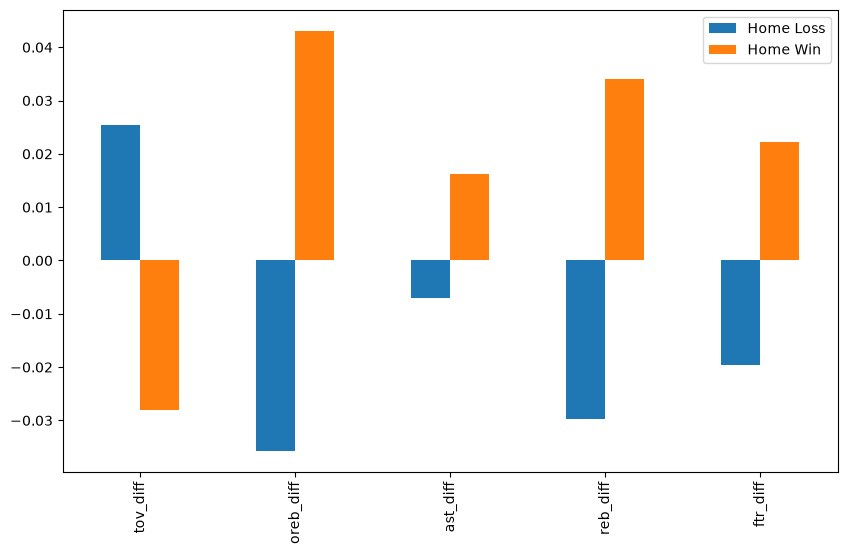

In [102]:
plot_data.plot (kind="bar", figsize=(10, 6))

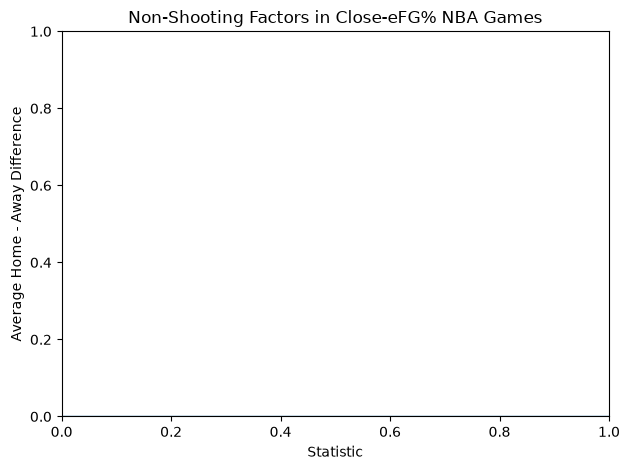

In [103]:
plt.axhline(0, linewidth=1)
plt.ylabel("Average Home - Away Difference")
plt.xlabel("Statistic")
plt.title("Non-Shooting Factors in Close-eFG% NBA Games")
plt.xticks(rotation=0)
plt.tight_layout()

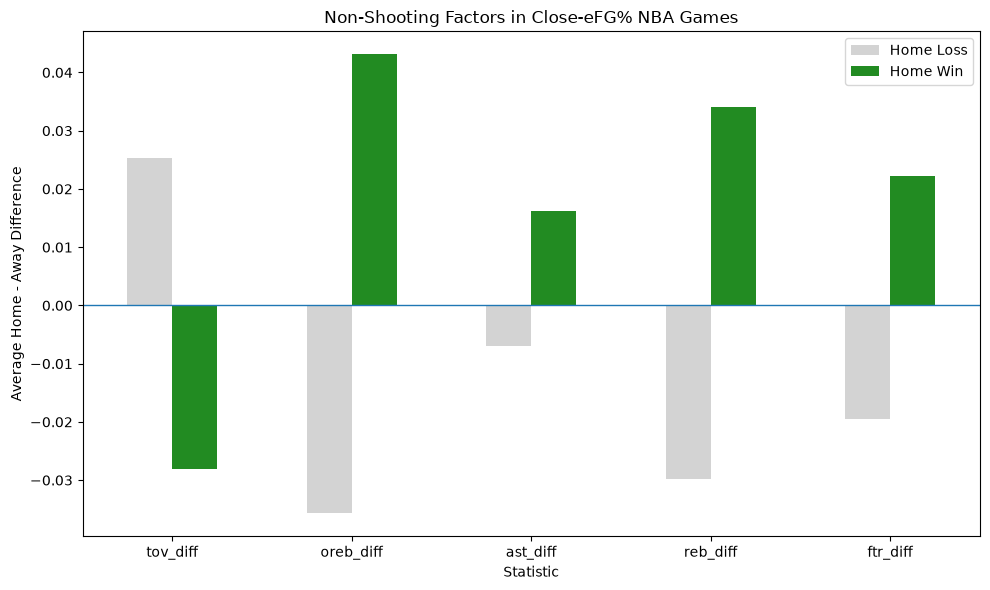

In [104]:
import matplotlib.pyplot as plt

plot_data = comparison.T
plot_data.columns = ["Home Loss", "Home Win"]

plot_data.plot(kind="bar", figsize=(10, 6), color=['lightgray', 'forestgreen'])

plt.axhline(0, linewidth=1)
plt.ylabel("Average Home - Away Difference")
plt.xlabel("Statistic")
plt.title("Non-Shooting Factors in Close-eFG% NBA Games")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../figures/win_loss_factor_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Axes: >

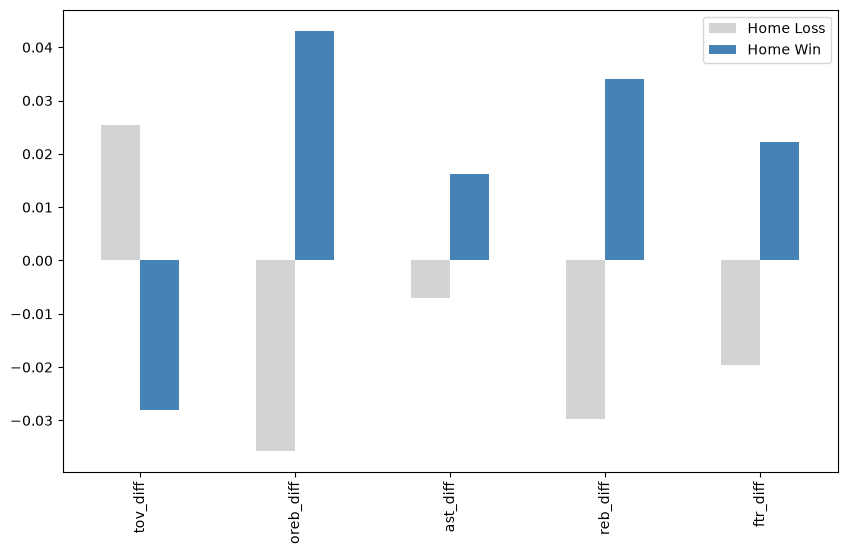

In [105]:
plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    color=["lightgray", "steelblue"]
)

In [106]:
close_shooting[["oreb_diff", "reb_diff"]].corr()

,oreb_diff,reb_diff
oreb_diff,1.000000,0.974301
reb_diff,0.974301,1.000000


In [107]:
from sklearn.model_selection import train_test_split

x = close_shooting[
    ["tov_diff", "oreb_diff", "ast_diff", "ftr_diff"]
]

y = close_shooting["home_win"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=.25, random_state=42, stratify=y )

print("Training games:", len(x_train))
print("Testing games:", len(x_test))


Training games: 157
Testing games: 53


In [108]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [109]:
accuracy = model.score(x_test, y_test)

print("Test accuracy:", accuracy)

Test accuracy: 0.6981132075471698


In [110]:
coefficients = pd.Series ( model.coef_[0], index=x.columns )
coefficients.sort_values(ascending=False)

oreb_diff    2.558009
ftr_diff     1.514348
ast_diff     0.527982
tov_diff    -1.871501
dtype: float64

In [111]:
baseline_accuracy = max(
    y_test.mean(),
    1 - y_test.mean()
)

print("Model accuracy:", model.score(x_test, y_test))
print("Baseline accuracy:", baseline_accuracy)

Model accuracy: 0.6981132075471698
Baseline accuracy: 0.5471698113207547


In [112]:
from sklearn.metrics import confusion_matrix

y_pred = model.predict(x_test)

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[11 13]
 [ 3 26]]


In [113]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(x_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.7514367816091955


In [114]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaled_model = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

scaled_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['tov_diff','oreb_diff','ast_diff','ftr_diff']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [115]:
print("Scaled model accuracy:", scaled_model.score(x_test, y_test))

scaled_prob = scaled_model.predict_proba(x_test)[:, 1]

print("Scaled ROC-AUC:", roc_auc_score(y_test, scaled_prob))

Scaled model accuracy: 0.8679245283018868
Scaled ROC-AUC: 0.939655172413793


In [116]:
scaled_logistic = scaled_model.named_steps["logisticregression"]

scaled_coefficients = pd.Series(
    scaled_logistic.coef_[0],
    index=x.columns
)

scaled_coefficients.sort_values(ascending=False, inplace=True)

In [117]:

scaled_logistic = scaled_model.named_steps["logisticregression"]

scaled_coefficients = pd.Series(
    scaled_logistic.coef_[0],
    index=x.columns
)

scaled_coefficients.sort_values(ascending=False)

oreb_diff    2.299679
ftr_diff     1.088098
ast_diff     0.157115
tov_diff    -2.515924
dtype: float64

In [118]:
scaled_pred = scaled_model.predict(x_test)

confusion_matrix(y_test, scaled_pred)

array([[20,  4],
       [ 3, 26]])

In [119]:
from sklearn.model_selection import cross_val_score

cv_accuracy = cross_val_score(
    scaled_model,
    x,
    y,
    cv=5,
    scoring="accuracy"
)

cv_auc = cross_val_score(
    scaled_model,
    x,
    y,
    cv=5,
    scoring="roc_auc"
)

print("CV accuracy scores:", cv_accuracy)
print("Mean CV accuracy:", cv_accuracy.mean())

print("CV ROC-AUC scores:", cv_auc)
print("Mean CV ROC-AUC:", cv_auc.mean())

CV accuracy scores: [0.85714286 0.9047619  0.97619048 0.83333333 0.83333333]
Mean CV accuracy: 0.880952380952381
CV ROC-AUC scores: [0.92448513 0.96796339 1.         0.92272727 0.94090909]
Mean CV ROC-AUC: 0.9512169752444353


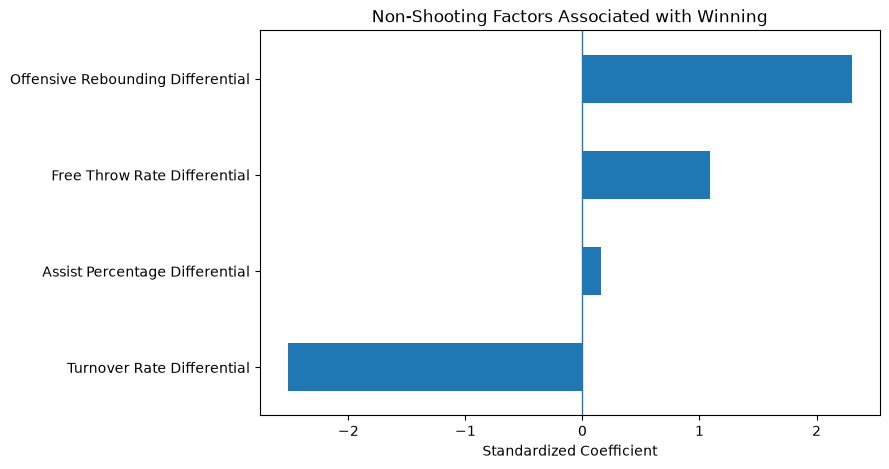

In [120]:
coef_plot = scaled_coefficients.rename({
    "tov_diff": "Turnover Rate Differential",
    "oreb_diff": "Offensive Rebounding Differential",
    "ftr_diff": "Free Throw Rate Differential",
    "ast_diff": "Assist Percentage Differential"
}).sort_values()

coef_plot.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.axvline(0, linewidth=1)
plt.xlabel("Standardized Coefficient")
plt.title("Non-Shooting Factors Associated with Winning")

plt.savefig(
    "../figures/standardized_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()